# Datathon Task 1 V6 — Stable Multi-Rank Low-Rank Hybrid

## 1. Objective, hypotheses, and success criteria

V5 finished in only 9m39s and its strongest new signal was Direct Low-Rank: its blend weight increased from 40% at h5 to almost 60% at h15. V6 therefore spends the remaining compute budget on the evidence-backed component, not on a larger graph network.

**Hypotheses**

1. Different latent ranks and ridge strengths capture different city-state time scales.
2. Persisting the road-specific residual can restore local detail removed by PCA, mainly at h5.
3. Ensemble weights that agree across two disjoint validation halves should generalize better than same-fold weights.

**Success criteria:** primary metric is cross-fitted inferred-test-weighted MSE. The final robust weights are the average of two complementary calibration halves. V5's 31.0305 same-fold weighted score is shown only as a reference, not as a fair cross-fit threshold.


In [1]:
from __future__ import annotations

import copy, gc, importlib, json, os, random, time
from dataclasses import dataclass, asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm, trange

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

BASE_SEED=42; V1_REFERENCE_MSE=27.8935; V2_REFERENCE_MSE=27.426926
HORIZONS=(5,10,15); N_ROADS=1260; HISTORY=15
KAGGLE_INPUT=Path('/kaggle/input/competitions/datathon-task-1/dataset-task1')
LOCAL_CANDIDATES=[Path.cwd()/'dataset-task1']+[p/'dataset-task1' for p in Path.cwd().parents]
LOCAL_INPUT=next((p for p in LOCAL_CANDIDATES if p.exists()),LOCAL_CANDIDATES[0])
DATA_DIR=KAGGLE_INPUT if KAGGLE_INPUT.exists() else LOCAL_INPUT
IS_KAGGLE=KAGGLE_INPUT.exists(); FAST_MODE=os.getenv('DATATON_FAST_MODE','0')=='1'
OUTPUT_DIR=Path('/kaggle/working') if IS_KAGGLE else DATA_DIR.parent/'tmp/jupyter-notebook/v6-smoke'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

VAL_STEPS=720 if not FAST_MODE else 120
EXPERIMENT_STRIDE=2 if not FAST_MODE else 40
FINAL_STRIDE=1 if not FAST_MODE else 40
PCA_DIM=48 if not FAST_MODE else 8; TEXT_DIM=32 if not FAST_MODE else 8
HIDDEN_DIM=64 if not FAST_MODE else 16
EXPERIMENT_EPOCHS=10 if not FAST_MODE else 1
SEED_SEARCH_EPOCHS=12 if not FAST_MODE else 1
PATIENCE=3; SEEDS=[42,2026] if not FAST_MODE else [42]
BATCH_SIZE=16 if torch.cuda.is_available() else (4 if not FAST_MODE else 2)
NUM_WORKERS=0
DEVICE=torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))

if not hasattr(torch,'_utils'): torch._utils=importlib.import_module('torch._utils')
probe=nn.Parameter(torch.tensor([1.])); opt=torch.optim.AdamW([probe],lr=1e-3)
(probe**2).sum().backward(); opt.step(); del probe,opt

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(BASE_SEED)
print('Optimizer preflight OK | torch',torch.__version__)
print({'data':str(DATA_DIR),'output':str(OUTPUT_DIR),'device':str(DEVICE),'fast_mode':FAST_MODE,
       'experiment_stride':EXPERIMENT_STRIDE,'final_stride':FINAL_STRIDE,'num_workers':NUM_WORKERS})
assert DATA_DIR.exists(),f'Dataset tidak ditemukan: {DATA_DIR}'


Optimizer preflight OK | torch 2.10.0+cu128
{'data': '/kaggle/input/competitions/datathon-task-1/dataset-task1', 'output': '/kaggle/working', 'device': 'cuda', 'fast_mode': False, 'experiment_stride': 2, 'final_stride': 1, 'num_workers': 0}


## 2. Load data dan EDA

EDA tidak hanya dekoratif. Kita memeriksa tiga hal yang langsung menentukan preprocessing/model: distribution shift m1–m2, prevalensi nol, serta sparsity/direction graph. Tabel selalu dicetak bersama plot agar hasil tetap machine-readable.


,split,shape,mean,std,zero_%,min,max
0,train_speed_m1_1_11160,"(11160, 1260)",54.992,17.048,1.036,0.0,142.0
1,train_speed_m2_1_5039,"(5039, 1260)",49.184,26.218,16.672,0.0,151.0
2,test_history,"(540, 15, 1260)",52.729,20.416,5.937,0.0,137.0


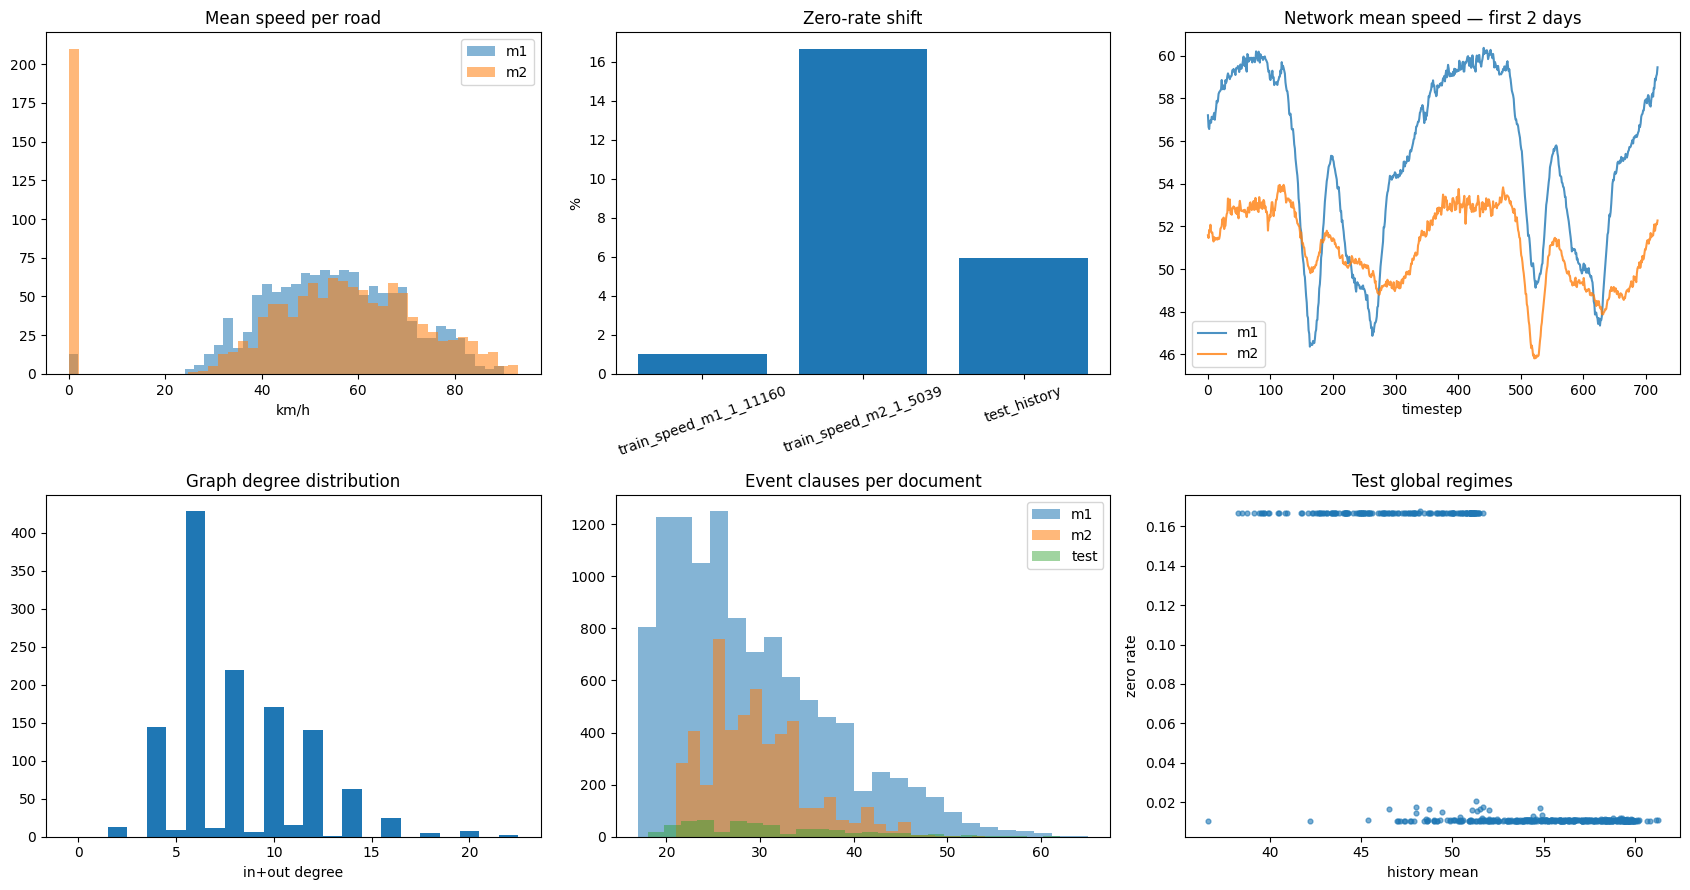

Graph nonzero incl diagonal: 5122 | degree min/median/max: 2 8.0 22
Text clauses median m1/m2/test: 27.0 28.0 29.0


In [2]:
def load_json_values(path):
    with Path(path).open() as f: return list(json.load(f).values())

speed_paths=sorted((DATA_DIR/'train').glob('train_speed_*.npy'))
text_paths=sorted((DATA_DIR/'train').glob('train_text_*.json'))
train_speeds=[np.load(p,mmap_mode='r') for p in speed_paths]
train_texts=[load_json_values(p) for p in text_paths]
test_hist=np.load(DATA_DIR/'test/test_X_hist.npy')
test_texts=load_json_values(DATA_DIR/'test/test_texts.json')
adjacency=np.load(DATA_DIR/'static/matrix.npy')
sample_submission=pd.read_csv(DATA_DIR/'sample_submission.csv')
assert [z.shape[1] for z in train_speeds]==[N_ROADS,N_ROADS]
assert test_hist.shape[1:]==(HISTORY,N_ROADS) and adjacency.shape==(N_ROADS,N_ROADS)

summary=pd.DataFrame([
    {'split':p.stem,'shape':str(z.shape),'mean':float(z.mean()),'std':float(z.std()),
     'zero_%':100*float(np.mean(z==0)),'min':float(z.min()),'max':float(z.max())}
    for p,z in zip(speed_paths,train_speeds)
]+[{'split':'test_history','shape':str(test_hist.shape),'mean':float(test_hist.mean()),
    'std':float(test_hist.std()),'zero_%':100*float(np.mean(test_hist==0)),
    'min':float(test_hist.min()),'max':float(test_hist.max())}])
display(summary.round(3))

src_all,dst_all=np.nonzero(adjacency!=0)
degree=np.bincount(np.r_[src_all,dst_all],minlength=N_ROADS)
doc_lengths=[[len([q for q in x.split('.') if q.strip()]) for x in block] for block in train_texts]
test_doc_lengths=[len([q for q in x.split('.') if q.strip()]) for x in test_texts]

fig,ax=plt.subplots(2,3,figsize=(17,9))
for z,label in zip(train_speeds,['m1','m2']): ax[0,0].hist(np.asarray(z).mean(0),bins=45,alpha=.55,label=label)
ax[0,0].set(title='Mean speed per road',xlabel='km/h'); ax[0,0].legend()
ax[0,1].bar(summary['split'],summary['zero_%']); ax[0,1].set(title='Zero-rate shift',ylabel='%'); ax[0,1].tick_params(axis='x',rotation=20)
for z,label in zip(train_speeds,['m1','m2']): ax[0,2].plot(np.asarray(z[:720]).mean(1),label=label,alpha=.8)
ax[0,2].set(title='Network mean speed — first 2 days',xlabel='timestep'); ax[0,2].legend()
ax[1,0].hist(degree,bins=np.arange(degree.max()+2)-.5); ax[1,0].set(title='Graph degree distribution',xlabel='in+out degree')
ax[1,1].hist(doc_lengths[0],bins=25,alpha=.55,label='m1'); ax[1,1].hist(doc_lengths[1],bins=25,alpha=.55,label='m2'); ax[1,1].hist(test_doc_lengths,bins=25,alpha=.45,label='test')
ax[1,1].set(title='Event clauses per document'); ax[1,1].legend()
test_global_mean=test_hist.mean((1,2)); test_zero=(test_hist==0).mean((1,2))
ax[1,2].scatter(test_global_mean,test_zero,s=12,alpha=.6); ax[1,2].set(title='Test global regimes',xlabel='history mean',ylabel='zero rate')
plt.tight_layout(); plt.show()
print('Graph nonzero incl diagonal:',int(np.count_nonzero(adjacency)),'| degree min/median/max:',int(degree.min()),float(np.median(degree)),int(degree.max()))
print('Text clauses median m1/m2/test:',np.median(doc_lengths[0]),np.median(doc_lengths[1]),np.median(test_doc_lengths))


### EDA interpretation

- m2 memiliki zero-rate jauh lebih tinggi daripada m1; nol dipertahankan dan diberikan sebagai mask, bukan diimputasi buta.
- Graph sparse dan directed; incoming/outgoing aggregation dipisahkan.
- Test terlihat sebagai dua cluster global. Kita ukur ini secara eksplisit di bagian regime.
- Recent-history smoothing tetap menjadi base forecast karena linear trend sebelumnya mudah meledak pada metric MSE.


## 3. Purged randomized-day validation

Hari dibagi deterministically ke lima kelompok; satu kelompok menjadi validation dan seluruh window yang menyentuh boundary dipurge. Protocol ini mengikuti notebook Malfa public 37.1 dan jauh lebih representative daripada easy-tail V3. Score utama tetap `test_weighted` 68.9/31.1.


In [3]:
DAY_LEN = 360        # 1 hari = 360 timestep (asumsi step 4 menit -> 24*60/4 = 360)
N_FOLDS = 5
PURGE = 15
HOLDOUT_FOLD = 0      # fold yang jadi validation tunggal untuk diagnostic run ini

def valid_times(n,start,stop,stride=1):
    return np.arange(max(HISTORY-1,start),min(stop,n-max(HORIZONS)),stride,dtype=np.int32)

def build_day_fold_seq(z_len, day_len=DAY_LEN, n_folds=N_FOLDS, seed=BASE_SEED):
    n_days = int(np.ceil(z_len / day_len))
    rng = np.random.default_rng(seed)
    order = np.arange(n_days); rng.shuffle(order)
    fold_of_day = np.empty(n_days, dtype=np.int32)
    for i, d in enumerate(order):
        fold_of_day[d] = i % n_folds
    fold_seq = fold_of_day[np.arange(z_len) // day_len]
    return fold_of_day, fold_seq

def split_purged_day_block(z_len, fold_seq, holdout_fold=HOLDOUT_FOLD, purge=PURGE):
    all_t = valid_times(z_len, HISTORY-1, z_len, 1)
    max_h = max(HORIZONS)
    train_list, val_list = [], []
    for t in all_t:
        core_lo, core_hi = t - HISTORY + 1, t + max_h
        buf_lo, buf_hi = max(0, core_lo - purge), min(z_len - 1, core_hi + purge)
        core = fold_seq[core_lo:core_hi + 1]
        buf = fold_seq[buf_lo:buf_hi + 1]
        if np.all(core == holdout_fold):
            val_list.append(t)
        elif not np.any(buf == holdout_fold):
            train_list.append(t)
        # else: zona purge -> dibuang, tidak dipakai train maupun val
    return np.asarray(train_list, dtype=np.int32), np.asarray(val_list, dtype=np.int32)

fold_maps = []; train_full_times = []; val_times = []
for z in train_speeds:
    fold_of_day, fold_seq = build_day_fold_seq(len(z))
    fold_maps.append(fold_of_day)
    tr, va = split_purged_day_block(len(z), fold_seq)
    train_full_times.append(tr); val_times.append(va)

experiment_times = [t[::EXPERIMENT_STRIDE] for t in train_full_times]
final_train_times = [t[::FINAL_STRIDE] for t in train_full_times]

# boolean row-mask per block (dipakai CELL 11 untuk fit PCA supaya tidak menyentuh hari held-out)
train_row_mask = [fold_of_day[np.arange(len(z)) // DAY_LEN] != HOLDOUT_FOLD
                   for z, fold_of_day in zip(train_speeds, fold_maps)]

if FAST_MODE:
    experiment_times=[t[-min(80,len(t)):] for t in experiment_times]
    final_train_times=[t[-min(100,len(t)):] for t in final_train_times]
    val_times=[t[-min(24,len(t)):] for t in val_times]

def collect_histories_targets(times_by_block,desc='collect windows'):
    hist=[]; targets=[]
    total=sum(len(x) for x in times_by_block)
    with tqdm(total=total,desc=desc,leave=False) as bar:
        for z,times in zip(train_speeds,times_by_block):
            for t in times:
                hist.append(np.asarray(z[t-HISTORY+1:t+1],dtype=np.float32))
                targets.append(np.stack([z[t+h] for h in HORIZONS],axis=-1).astype(np.float32)); bar.update()
    return np.stack(hist),np.stack(targets)

val_hist,val_y=collect_histories_targets(val_times,'validation windows')
VAL_LENGTHS=[len(x) for x in val_times]
print('Hari per fold tiap block:',[np.bincount(fm, minlength=N_FOLDS).tolist() for fm in fold_maps])
print('Experiment train:',[len(x) for x in experiment_times])
print('Final stride-1 train:',[len(x) for x in final_train_times])
print('Validation (purged day-block, holdout fold=%d):'%HOLDOUT_FOLD,VAL_LENGTHS,val_hist.shape,val_y.shape)

def horizon_mse(y,pred): return np.array([np.mean((y[...,i]-pred[...,i])**2) for i in range(3)])
def block_horizon_mse(y,pred,lengths=VAL_LENGTHS):
    cut=lengths[0]
    return np.stack([horizon_mse(y[:cut],pred[:cut]),horizon_mse(y[cut:cut+lengths[1]],pred[cut:cut+lengths[1]])])

Hari per fold tiap block: [[7, 6, 6, 6, 6], [3, 3, 3, 3, 2]]
Experiment train: [4151, 1877]
Final stride-1 train: [8301, 3753]
Validation (purged day-block, holdout fold=0): [2346, 993] (3339, 15, 1260) (3339, 1260, 3)


## 4. Reverse engineering regime

Fitur regime hanya memakai history yang tersedia: mean, standard deviation, dan zero-rate lintas 1.260 road untuk masing-masing 15 lag (45 fitur). Logistic regression bukan model target speed; ia hanya menghasilkan probabilitas konteks m2-like. Jika probabilitas test tidak jelas, soft gating akan tetap interpolate—berbeda dari hard expert.


,val_accuracy,val_auc,val_logloss,test_m1_like,test_m2_like,test_m1_weight,test_m2_weight
0,1.0,1.0,0.000321,372,168,0.688896,0.311104


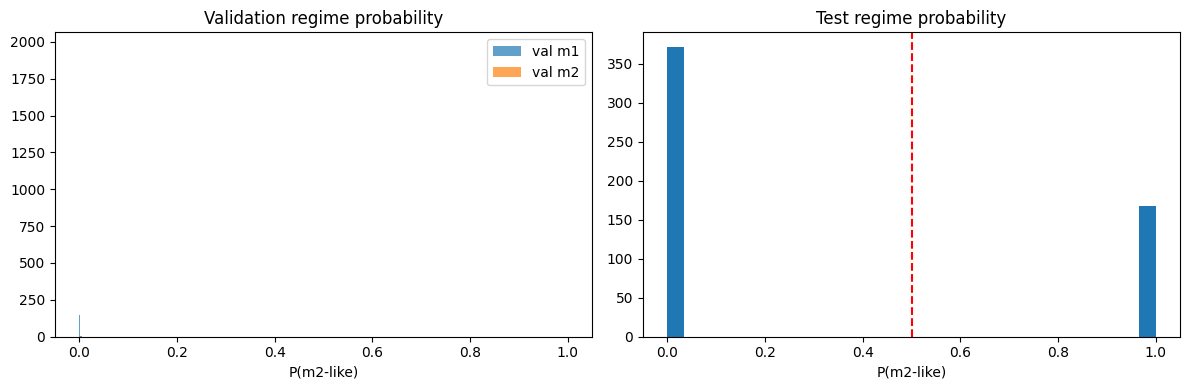

Inferred test block weights: {'m1': np.float64(0.688896), 'm2': np.float64(0.311104)}


In [4]:
def global_features_from_histories(histories,batch=128,desc='global features'):
    out=[]
    for start in tqdm(range(0,len(histories),batch),desc=desc,leave=False):
        x=np.asarray(histories[start:start+batch],dtype=np.float32)
        out.append(np.concatenate([x.mean(2),x.std(2),(x==0).mean(2)],axis=1).astype(np.float32))
    return np.concatenate(out)

def global_features_for_times(times_by_block,batch=128,desc='train global features'):
    out=[]; labels=[]
    total=sum((len(t)+batch-1)//batch for t in times_by_block)
    with tqdm(total=total,desc=desc,leave=False) as bar:
        for b,(z,times) in enumerate(zip(train_speeds,times_by_block)):
            parts=[]
            for start in range(0,len(times),batch):
                ts=times[start:start+batch]
                w=np.stack([z[t-HISTORY+1:t+1] for t in ts]).astype(np.float32)
                parts.append(np.concatenate([w.mean(2),w.std(2),(w==0).mean(2)],axis=1)); bar.update()
            out.append(np.concatenate(parts)); labels.extend([b]*len(times))
    return np.concatenate(out).astype(np.float32),np.asarray(labels)

global_train,regime_train_y=global_features_for_times(experiment_times)
global_val=global_features_from_histories(val_hist,desc='validation regime features')
global_test=global_features_from_histories(test_hist,desc='test regime features')
global_scaler=StandardScaler().fit(global_train)
regime_clf=LogisticRegression(C=.1,max_iter=1000,random_state=BASE_SEED).fit(global_scaler.transform(global_train),regime_train_y)
val_regime_y=np.r_[np.zeros(VAL_LENGTHS[0],dtype=int),np.ones(VAL_LENGTHS[1],dtype=int)]
val_regime_p=regime_clf.predict_proba(global_scaler.transform(global_val))[:,1]
test_regime_p=regime_clf.predict_proba(global_scaler.transform(global_test))[:,1]
TEST_BLOCK_WEIGHTS=np.array([np.mean(1-test_regime_p),np.mean(test_regime_p)])

regime_report=pd.DataFrame([{
    'val_accuracy':accuracy_score(val_regime_y,val_regime_p>=.5),
    'val_auc':roc_auc_score(val_regime_y,val_regime_p),
    'val_logloss':log_loss(val_regime_y,val_regime_p),
    'test_m1_like':int(np.sum(test_regime_p<.5)),'test_m2_like':int(np.sum(test_regime_p>=.5)),
    'test_m1_weight':TEST_BLOCK_WEIGHTS[0],'test_m2_weight':TEST_BLOCK_WEIGHTS[1]}])
display(regime_report.round(6))
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(val_regime_p[:VAL_LENGTHS[0]],bins=20,alpha=.7,label='val m1'); ax[0].hist(val_regime_p[VAL_LENGTHS[0]:],bins=20,alpha=.7,label='val m2'); ax[0].set(title='Validation regime probability',xlabel='P(m2-like)'); ax[0].legend()
ax[1].hist(test_regime_p,bins=30); ax[1].axvline(.5,color='red',ls='--'); ax[1].set(title='Test regime probability',xlabel='P(m2-like)')
plt.tight_layout(); plt.show()
print('Inferred test block weights:',dict(zip(['m1','m2'],TEST_BLOCK_WEIGHTS.round(6))))


## 5. Strong non-neural anchors: AR dan PCA residual

Shared AR memodelkan perubahan dari latest speed dan menjadi anchor konservatif. PCA residual menangkap city-wide low-rank state yang tidak mudah ditangkap per-road AR. Eksperimen manual KNN analog, per-road graph ridge, dan LightGBM residual lebih buruk (38.59, 29.55, dan 30.06), sehingga tidak membebani notebook final.


PCA ridge horizons: 100%|██████████| 3/3 [00:01<00:00,  2.04it/s]


,model,h5,h10,h15,mean
0,AR,36.47958,45.401112,52.653759,44.844818
1,PCA,33.45290,38.060959,40.857079,37.456982


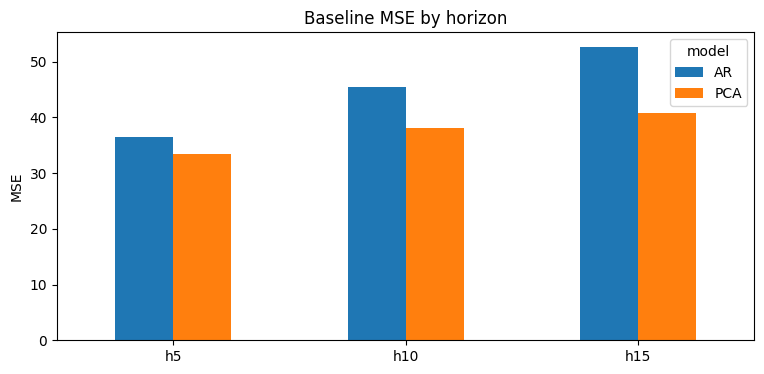

DirectLR validation sweep: 100%|██████████| 9/9 [00:07<00:00,  1.16it/s]


,model,rank,alpha,residual,h5,h10,h15,balanced_mean,test_weighted_mean
0,DLR_r48_a30_resid_soft,48,30.0,resid_soft,28.329180,30.142879,31.782471,30.084841,32.24940
1,DLR_r64_a30_resid_soft,64,30.0,resid_soft,28.231119,30.170839,31.824980,30.075640,32.25496
2,DLR_r64_a100_resid_soft,64,100.0,resid_soft,28.258400,30.232031,31.919121,30.136520,32.32817
3,DLR_r48_a100_resid_soft,48,100.0,resid_soft,28.364340,30.215561,31.893330,30.157740,32.33637
4,DLR_r80_a30_resid_soft,80,30.0,resid_soft,28.281919,30.342270,31.993120,30.205770,32.40249
5,DLR_r64_a300_resid_soft,64,300.0,resid_soft,28.323360,30.350880,32.080090,30.251440,32.46363
6,DLR_r48_a30_base,48,30.0,base,28.579679,30.210421,31.877720,30.222601,32.47321
7,DLR_r80_a100_resid_soft,80,100.0,resid_soft,28.309450,30.403650,32.086590,30.266560,32.47585
8,DLR_r64_a30_base,64,30.0,base,28.481621,30.238390,31.920231,30.213421,32.47878
9,DLR_r48_a300_resid_soft,48,300.0,resid_soft,28.443020,30.355101,32.084721,30.294279,32.49774


Selected complementary DirectLR variants: ['DLR_r48_a30_resid_soft', 'DLR_r64_a30_resid_soft']


In [5]:
def fit_shared_ar(times_by_block,max_timestamps_per_block=1400,alpha=1000.,seed=BASE_SEED):
    rng=np.random.default_rng(seed); xs=[]; ys={h:[] for h in HORIZONS}
    for z,times in zip(train_speeds,times_by_block):
        take=min(len(times),max_timestamps_per_block if not FAST_MODE else 40)
        chosen=np.sort(rng.choice(times,size=take,replace=False))
        w=np.stack([z[t-HISTORY+1:t+1] for t in chosen]).astype(np.float32)
        xs.append((w-w[:,-1:]).transpose(0,2,1).reshape(-1,HISTORY))
        for h in HORIZONS: ys[h].append((z[chosen+h]-z[chosen]).reshape(-1).astype(np.float32))
    X=np.concatenate(xs); return {h:Ridge(alpha=alpha).fit(X,np.concatenate(ys[h])) for h in HORIZONS}

def predict_ar_histories(models,histories,batch=256,desc=None):
    out=[]; iterator=range(0,len(histories),batch)
    if desc: iterator=tqdm(iterator,desc=desc,leave=False)
    for start in iterator:
        w=np.asarray(histories[start:start+batch],dtype=np.float32)
        x=(w-w[:,-1:]).transpose(0,2,1).reshape(-1,HISTORY); latest=w[:,-1].reshape(-1)
        out.append(np.stack([(latest+models[h].predict(x)).reshape(len(w),N_ROADS) for h in HORIZONS],axis=-1))
    return np.concatenate(out).astype(np.float32)

ar_val_models=fit_shared_ar(experiment_times)
val_pred_ar=predict_ar_histories(ar_val_models,val_hist,desc='AR validation')

def fit_road_pca(row_masks,n_components=PCA_DIM):
    rows=np.concatenate([np.asarray(z,dtype=np.float32)[mask] for z,mask in zip(train_speeds,row_masks)])
    model=PCA(n_components=n_components,whiten=True,svd_solver='randomized',random_state=BASE_SEED).fit(rows)
    del rows; gc.collect(); return model
def summary_from_windows(w):
    return np.stack([w[:,0:3].mean(1),w[:,5:8].mean(1),w[:,10:13].mean(1),w[:,-3:].mean(1),w[:,-1]-w[:,-5]],axis=1)
def pca_features_hist(pca,histories,batch=128,desc='PCA features'):
    out=[]
    for start in tqdm(range(0,len(histories),batch),desc=desc,leave=False):
        s=summary_from_windows(np.asarray(histories[start:start+batch],dtype=np.float32))
        out.append(np.concatenate([pca.transform(s[:,k]) for k in range(5)],axis=1))
    return np.concatenate(out).astype(np.float32)
def pca_features_times(pca,times_by_block,batch=128):
    out=[]
    for z,times in zip(train_speeds,times_by_block):
        for start in tqdm(range(0,len(times),batch),desc='PCA train block',leave=False):
            ts=times[start:start+batch]; w=np.stack([z[t-HISTORY+1:t+1] for t in ts]).astype(np.float32)
            s=summary_from_windows(w); out.append(np.concatenate([pca.transform(s[:,k]) for k in range(5)],axis=1))
    return np.concatenate(out).astype(np.float32)
def targets_bases(times_by_block,ar_models,batch=128):
    yy=[]; bb=[]
    for z,times in zip(train_speeds,times_by_block):
        for start in tqdm(range(0,len(times),batch),desc='PCA targets',leave=False):
            ts=times[start:start+batch]; w=np.stack([z[t-HISTORY+1:t+1] for t in ts]).astype(np.float32)
            yy.append(np.stack([z[ts+h] for h in HORIZONS],axis=-1)); bb.append(predict_ar_histories(ar_models,w))
    return np.concatenate(yy).astype(np.float32),np.concatenate(bb).astype(np.float32)

pca_val=fit_road_pca(train_row_mask); Fp_train=pca_features_times(pca_val,experiment_times); Fp_val=pca_features_hist(pca_val,val_hist)
Yp,Bp=targets_bases(experiment_times,ar_val_models)
pca_alphas=[1e2,1e4,1e5] if not FAST_MODE else [1e4]
pca_models={}; pca_best_alpha={}; pca_parts=[]
for i,h in enumerate(tqdm(HORIZONS,desc='PCA ridge horizons')):
    best=(float('inf'),None,None,None); residual=Yp[...,i]-Bp[...,i]
    for alpha in pca_alphas:
        m=Ridge(alpha=alpha).fit(Fp_train,residual); pred=val_pred_ar[...,i]+m.predict(Fp_val)
        score=np.mean((val_y[...,i]-pred)**2)
        if score<best[0]: best=(score,alpha,m,pred.astype(np.float32))
    _,pca_best_alpha[h],pca_models[h],pred=best; pca_parts.append(pred)
val_pred_pca=np.stack(pca_parts,axis=-1); del Yp,Bp; gc.collect()
baseline=pd.DataFrame({'model':['AR','PCA'],'h5':[horizon_mse(val_y,val_pred_ar)[0],horizon_mse(val_y,val_pred_pca)[0]],
                       'h10':[horizon_mse(val_y,val_pred_ar)[1],horizon_mse(val_y,val_pred_pca)[1]],
                       'h15':[horizon_mse(val_y,val_pred_ar)[2],horizon_mse(val_y,val_pred_pca)[2]]})
baseline['mean']=baseline[['h5','h10','h15']].mean(1); display(baseline.round(5))
baseline.set_index('model')[['h5','h10','h15']].T.plot(kind='bar',figsize=(9,4),title='Baseline MSE by horizon'); plt.ylabel('MSE'); plt.xticks(rotation=0); plt.show()


# V6 rapid component: Raphael-inspired direct city-state forecast.

DIRECT_RANKS=[48,64,80] if not FAST_MODE else [4,8]
DIRECT_ALPHAS=[30.,100.,300.] if not FAST_MODE else [100.]
RESIDUAL_VARIANTS={
    'base':(0.,0.,0.),
    'resid_soft':(.30,.15,.05),
    'resid_strong':(.55,.30,.15),
}

class DirectLowRankFamily:
    """One maximum PCA, then a compact rank/regularization family.

    PCA represents the joint city state. The optional residual persistence restores
    road-local information that is deliberately absent from the low-rank state.
    """
    def __init__(self,max_rank,specs):
        self.max_rank=int(max_rank); self.specs=list(specs); self.models={}
    def fit(self,times_by_block,row_masks):
        rows=np.concatenate([np.asarray(z[mask],dtype=np.float32) for z,mask in zip(train_speeds,row_masks)])
        self.pca=PCA(n_components=self.max_rank,whiten=True,svd_solver='randomized',random_state=BASE_SEED).fit(rows)
        del rows; gc.collect()
        zblocks=[self.pca.transform(np.asarray(z,dtype=np.float32)).astype(np.float32) for z in train_speeds]
        ranks=sorted(set(int(r) for r,_ in self.specs))
        for rank in tqdm(ranks,desc='DirectLR ranks'):
            X=[]; Y=[]
            for zlat,times in zip(zblocks,times_by_block):
                X.append(np.stack([zlat[t-HISTORY+1:t+1,:rank].reshape(-1) for t in times]))
                Y.append(np.stack([np.concatenate([zlat[t+h,:rank] for h in HORIZONS]) for t in times]))
            X=np.concatenate(X).astype(np.float32); Y=np.concatenate(Y).astype(np.float32)
            for r,alpha in self.specs:
                if int(r)==rank:
                    self.models[(rank,float(alpha))]=Ridge(alpha=float(alpha)).fit(X,Y)
            del X,Y; gc.collect()
        del zblocks; gc.collect(); return self
    def _inverse_partial(self,z,rank):
        full=np.zeros((len(z),self.max_rank),dtype=np.float32); full[:,:rank]=z
        return self.pca.inverse_transform(full).astype(np.float32)
    def predict_base(self,histories,spec,batch=64,desc='DirectLR prediction'):
        rank,alpha=int(spec[0]),float(spec[1]); model=self.models[(rank,alpha)]; out=[]
        for start in tqdm(range(0,len(histories),batch),desc=desc,leave=False):
            w=np.asarray(histories[start:start+batch],dtype=np.float32)
            z=self.pca.transform(w.reshape(-1,N_ROADS)).reshape(len(w),HISTORY,self.max_rank)
            predz=model.predict(z[:,:,:rank].reshape(len(w),-1)).reshape(len(w),3,rank)
            out.append(np.stack([self._inverse_partial(predz[:,i],rank) for i in range(3)],axis=-1))
        return np.concatenate(out).astype(np.float32)
    def add_local_residual(self,base,histories,scales):
        if max(scales)==0: return base
        last=np.asarray(histories[:,-1],dtype=np.float32)
        last_recon=self.pca.inverse_transform(self.pca.transform(last)).astype(np.float32)
        residual=last-last_recon
        return (base+residual[...,None]*np.asarray(scales,dtype=np.float32)).astype(np.float32)

direct_specs=[(r,a) for r in DIRECT_RANKS for a in DIRECT_ALPHAS]
direct_lr_val_model=DirectLowRankFamily(max(DIRECT_RANKS),direct_specs).fit(final_train_times,train_row_mask)
direct_score_rows=[]; winner_registry={}
for spec in tqdm(direct_specs,desc='DirectLR validation sweep'):
    base=direct_lr_val_model.predict_base(val_hist,spec,desc=f'DirectLR r{spec[0]} a{spec[1]:g}')
    for residual_name,scales in RESIDUAL_VARIANTS.items():
        pred=direct_lr_val_model.add_local_residual(base,val_hist,scales)
        blocks=block_horizon_mse(val_y,pred); balanced=blocks.mean(0); weighted=TEST_BLOCK_WEIGHTS@blocks
        name=f'DLR_r{spec[0]}_a{spec[1]:g}_{residual_name}'
        row={'model':name,'rank':spec[0],'alpha':spec[1],'residual':residual_name,
             'h5':balanced[0],'h10':balanced[1],'h15':balanced[2],
             'balanced_mean':balanced.mean(),'test_weighted_mean':weighted.mean()}
        direct_score_rows.append(row)
        metrics={'mean':weighted.mean(),'h5':weighted[0],'h10':weighted[1],'h15':weighted[2]}
        for key,value in metrics.items():
            if key not in winner_registry or value<winner_registry[key]['score']:
                winner_registry[key]={'score':float(value),'name':name,'pred':pred.copy(),
                                      'spec':(int(spec[0]),float(spec[1])),'scales':tuple(scales)}
    del base; gc.collect()

direct_report=pd.DataFrame(direct_score_rows).sort_values('test_weighted_mean').reset_index(drop=True)
display(direct_report.head(12).round(5))
direct_selected={}
for info in winner_registry.values(): direct_selected[info['name']]=info
direct_selected_names=list(direct_selected)
direct_selected_predictions=[direct_selected[n]['pred'] for n in direct_selected_names]
print('Selected complementary DirectLR variants:',direct_selected_names)


## 6. Text preprocessing

Event text semi-terstruktur dan test mengandung kombinasi clause yang tidak selalu pernah terlihat verbatim. Word 1–3 gram TF-IDF dapat berbagi kata event/lokasi, lalu SVD memadatkannya agar road-specific gate tetap ringan.


In [6]:
all_train_text=[s for block in train_texts for s in block]
tfidf=TfidfVectorizer(ngram_range=(1,3),min_df=3,max_features=7000,sublinear_tf=True,dtype=np.float32)
text_sparse=tfidf.fit_transform(all_train_text)
text_dim_actual=min(TEXT_DIM,text_sparse.shape[1]-1)
text_svd=TruncatedSVD(n_components=text_dim_actual,n_iter=7,random_state=BASE_SEED)
all_text_z=text_svd.fit_transform(text_sparse).astype(np.float32)
test_text_z=text_svd.transform(tfidf.transform(test_texts)).astype(np.float32)
offsets=np.cumsum([0]+[len(x) for x in train_texts])
train_text_z=[all_text_z[offsets[i]:offsets[i+1]] for i in range(2)]
print('TF-IDF:',text_sparse.shape,'latent:',all_text_z.shape,'explained variance:',float(text_svd.explained_variance_ratio_.sum()))
del text_sparse,all_text_z; gc.collect()


TF-IDF: (16199, 2021) latent: (16199, 32) explained variance: 0.6661109924316406


2

## 7. Neural family: directed graph + text gate + global FiLM

Semua model memprediksi residual dari mean tiga speed terakhir. FiLM mengubah hidden representation road berdasarkan global trajectory dan regime probability. EMA adalah weight averaging, sedangkan soft-MoE mencampur dua output head menggunakan probabilitas regime. Ablation menjaga komponen lain sama agar kesimpulan kausal lebih masuk akal.


In [7]:
src_np,dst_np=np.nonzero(adjacency!=0); keep=src_np!=dst_np; src_np,dst_np=src_np[keep],dst_np[keep]
out_degree_np=np.bincount(src_np,minlength=N_ROADS).clip(min=1).astype(np.float32)
in_degree_np=np.bincount(dst_np,minlength=N_ROADS).clip(min=1).astype(np.float32)
norm_rows=np.concatenate([np.asarray(z,dtype=np.float32)[mask] for z,mask in zip(train_speeds,train_row_mask)])
road_mean=norm_rows.mean(0).astype(np.float32); road_std=(norm_rows.std(0)+3.).astype(np.float32); del norm_rows; gc.collect()

class TrafficDataset(Dataset):
    def __init__(self,times_by_block): self.index=[(b,int(t)) for b,times in enumerate(times_by_block) for t in times]
    def __len__(self): return len(self.index)
    def __getitem__(self,i):
        b,t=self.index[i]; z=train_speeds[b]
        hist=np.asarray(z[t-HISTORY+1:t+1],dtype=np.float32).T.copy()
        target=np.stack([z[t+h] for h in HORIZONS],axis=-1).astype(np.float32)
        return torch.from_numpy(hist),torch.from_numpy(train_text_z[b][t]),torch.from_numpy(target)

class DirectedGraphBlock(nn.Module):
    def __init__(self,hidden):
        super().__init__(); self.self_linear=nn.Linear(hidden,hidden); self.in_linear=nn.Linear(hidden,hidden,bias=False); self.out_linear=nn.Linear(hidden,hidden,bias=False); self.norm=nn.LayerNorm(hidden); self.dropout=nn.Dropout(.1)
    def forward(self,h,src,dst,in_degree,out_degree):
        incoming=torch.zeros_like(h); outgoing=torch.zeros_like(h)
        incoming.index_add_(1,dst,h[:,src]); outgoing.index_add_(1,src,h[:,dst])
        u=torch.nn.functional.gelu(self.self_linear(h)+self.in_linear(incoming/in_degree[None,:,None])+self.out_linear(outgoing/out_degree[None,:,None]))
        return self.norm(h+self.dropout(u))

@dataclass(frozen=True)
class ModelConfig:
    name:str; use_global:bool=False; use_ema:bool=False; use_moe:bool=False; zero_aux_weight:float=.1

class TrafficNetV3(nn.Module):
    def __init__(self,config,mean_np,std_np,global_scaler_local,regime_clf_local,hidden=HIDDEN_DIM):
        super().__init__(); self.config=config
        self.register_buffer('road_mean',torch.tensor(mean_np).view(1,N_ROADS,1)); self.register_buffer('road_std',torch.tensor(std_np).view(1,N_ROADS,1))
        self.register_buffer('src',torch.tensor(src_np,dtype=torch.long)); self.register_buffer('dst',torch.tensor(dst_np,dtype=torch.long)); self.register_buffer('in_degree',torch.tensor(in_degree_np)); self.register_buffer('out_degree',torch.tensor(out_degree_np))
        self.register_buffer('global_mean',torch.tensor(global_scaler_local.mean_,dtype=torch.float32)); self.register_buffer('global_scale',torch.tensor(global_scaler_local.scale_,dtype=torch.float32))
        raw_coef=regime_clf_local.coef_[0]/global_scaler_local.scale_; raw_intercept=regime_clf_local.intercept_[0]-np.sum(regime_clf_local.coef_[0]*global_scaler_local.mean_/global_scaler_local.scale_)
        self.register_buffer('regime_coef',torch.tensor(raw_coef,dtype=torch.float32)); self.register_buffer('regime_intercept',torch.tensor(raw_intercept,dtype=torch.float32))
        self.road_embedding=nn.Embedding(N_ROADS,12)
        self.history_encoder=nn.Sequential(nn.Linear(HISTORY*3+12,hidden),nn.GELU(),nn.Dropout(.1),nn.Linear(hidden,hidden),nn.GELU())
        gate_dim=16; self.text_context=nn.Sequential(nn.Linear(text_dim_actual,hidden),nn.GELU(),nn.Linear(hidden,hidden)); self.text_query=nn.Linear(text_dim_actual,gate_dim); self.road_event_embedding=nn.Embedding(N_ROADS,gate_dim)
        if config.use_global: self.film=nn.Sequential(nn.Linear(45+1+text_dim_actual,hidden),nn.GELU(),nn.Linear(hidden,hidden*2))
        self.graph_blocks=nn.ModuleList([DirectedGraphBlock(hidden),DirectedGraphBlock(hidden)])
        def make_heads(): return nn.ModuleList([nn.Sequential(nn.Linear(hidden,hidden//2),nn.GELU(),nn.Linear(hidden//2,1)) for _ in HORIZONS])
        self.heads_a=make_heads(); self.heads_b=make_heads() if config.use_moe else None; self.zero_head=nn.Linear(hidden,3)
        for heads in [self.heads_a,self.heads_b]:
            if heads is not None:
                for head in heads: nn.init.zeros_(head[-1].weight); nn.init.zeros_(head[-1].bias)
    def forward(self,hist,text):
        normalized=(hist-self.road_mean)/self.road_std; base=hist[:,:,-3:].mean(-1,keepdim=True); deviations=(hist-base)/self.road_std; zero=(hist==0).to(hist.dtype)
        ids=torch.arange(N_ROADS,device=hist.device); emb=self.road_embedding(ids)[None].expand(len(hist),-1,-1)
        h=self.history_encoder(torch.cat([normalized,deviations,zero,emb],-1))
        context=self.text_context(text)[:,None]; query=self.text_query(text); gate=torch.sigmoid(torch.einsum('bd,rd->br',query,self.road_event_embedding.weight)/(query.shape[-1]**.5)); h=h+gate[...,None]*context
        raw_global=torch.cat([hist.mean(1),hist.std(1,unbiased=False),(hist==0).to(hist.dtype).mean(1)],1)
        regime_p=torch.sigmoid(raw_global@self.regime_coef+self.regime_intercept)
        if self.config.use_global:
            gnorm=(raw_global-self.global_mean)/self.global_scale; gamma,beta=self.film(torch.cat([gnorm,regime_p[:,None],text],1)).chunk(2,1)
            h=h*(1+.15*torch.tanh(gamma[:,None]))+.15*beta[:,None]
        for block in self.graph_blocks: h=block(h,self.src,self.dst,self.in_degree,self.out_degree)
        ra=torch.cat([head(h) for head in self.heads_a],-1)
        if self.heads_b is not None:
            rb=torch.cat([head(h) for head in self.heads_b],-1); residual=(1-regime_p[:,None,None])*ra+regime_p[:,None,None]*rb
        else: residual=ra
        return base+residual*self.road_std,self.zero_head(h),regime_p

ABLATIONS=[ModelConfig('global_film_ema_soft_moe',use_global=True,use_ema=True,use_moe=True)]
display(pd.DataFrame([asdict(x) for x in ABLATIONS]))


,name,use_global,use_ema,use_moe,zero_aux_weight
0,global_film_ema_soft_moe,True,True,True,0.1


## 8. Training, ablation, dan evaluation diagnostics

Epoch, architecture, seed, dan inference loops memakai `tqdm`. Early stopping memilih test-weighted score, tetapi balanced dan block-specific MSE tetap tersimpan sebagai tulisan/CSV. EMA hanya dipakai pada config yang menyatakannya.


global_film_ema_soft_moe seed=42: 100%|██████████| 10/10 [01:07<00:00,  6.68s/it, balanced=32.056, train=33.935, weighted=34.514]
                                                                                                                                 
Architecture ablations: 100%|██████████| 1/1 [01:09<00:00, 69.68s/it]


,model,h5,h10,h15,balanced_mean,test_weighted_mean,m1_mean,m2_mean,best_epoch
0,global_film_ema_soft_moe,28.340281,32.382481,35.436859,32.0532,34.50009,38.530022,25.57638,9


Selected by inferred test-composition MSE: ModelConfig(name='global_film_ema_soft_moe', use_global=True, use_ema=True, use_moe=True, zero_aux_weight=0.1)


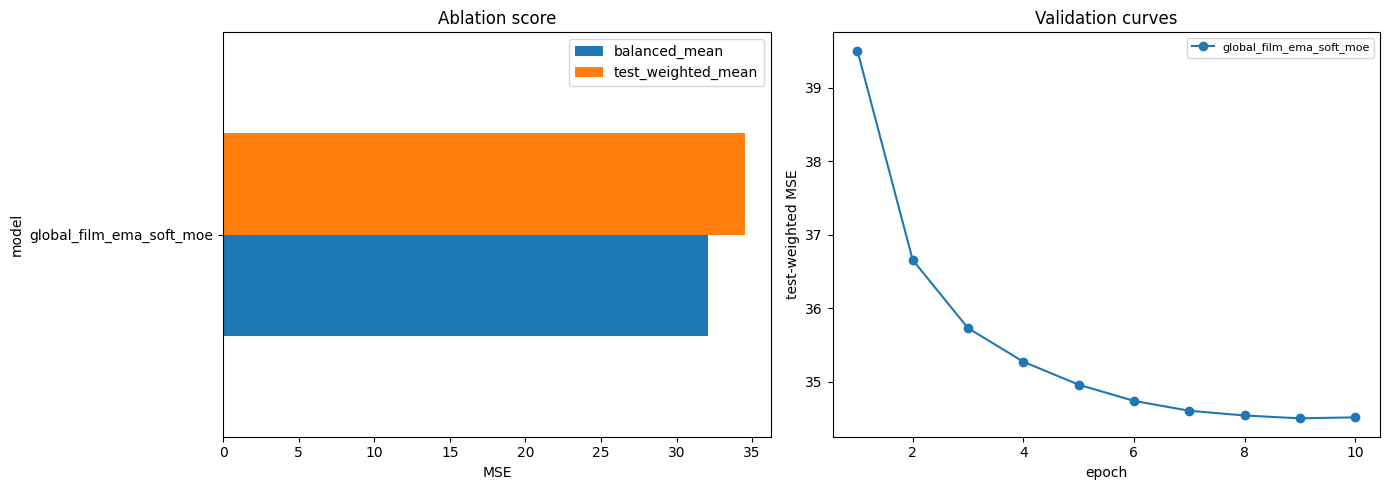

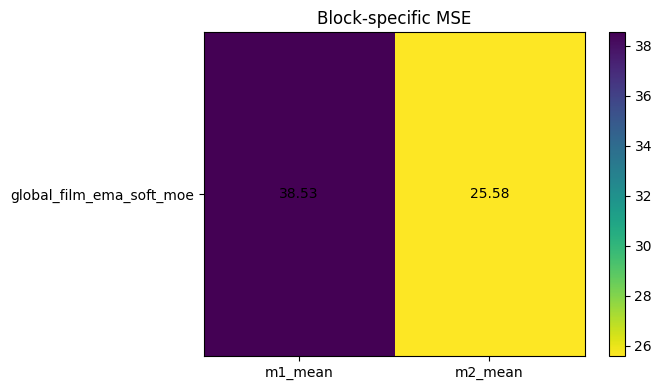

In [8]:
def make_loader(times,shuffle,seed,batch_size=BATCH_SIZE):
    g=torch.Generator(); g.manual_seed(seed)
    return DataLoader(TrafficDataset(times),batch_size=batch_size,shuffle=shuffle,num_workers=NUM_WORKERS,pin_memory=torch.cuda.is_available(),generator=g)

def evaluate_neural(model,loader,return_pred=False,desc=None):
    model.eval(); parts=[]
    with torch.no_grad():
        iterator=loader if desc is None else tqdm(loader,desc=desc,leave=False)
        for hist,text,target in iterator:
            pred,_,_=model(hist.to(DEVICE),text.to(DEVICE)); parts.append(pred.cpu().numpy())
    pred=np.concatenate(parts); scores=horizon_mse(val_y,pred) if len(pred)==len(val_y) else None
    return (scores,pred) if return_pred else scores

def score_details(y,pred):
    blocks=block_horizon_mse(y,pred); balanced=blocks.mean(0); weighted=TEST_BLOCK_WEIGHTS@blocks
    return blocks,balanced,weighted

@torch.no_grad()
def ema_update(ema_model,model,decay=.995):
    for ep,p in zip(ema_model.parameters(),model.parameters()): ep.mul_(decay).add_(p,alpha=1-decay)
    for eb,b in zip(ema_model.buffers(),model.buffers()): eb.copy_(b)

def train_neural(config,train_times_local,val_times_local,mean_np,std_np,scaler_local,clf_local,seed,epochs):
    set_seed(seed); train_loader=make_loader(train_times_local,True,seed); val_loader=make_loader(val_times_local,False,seed) if val_times_local is not None else None
    model=TrafficNetV3(config,mean_np,std_np,scaler_local,clf_local).to(DEVICE); ema_model=copy.deepcopy(model).eval() if config.use_ema else None
    optimizer=torch.optim.AdamW(model.parameters(),lr=2e-3,weight_decay=1e-4); scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=max(1,epochs)); pos_weight=torch.tensor(5.,device=DEVICE)
    best_state=None; best=float('inf'); best_epoch=0; stale=0; logs=[]
    bar=trange(1,epochs+1,desc=f'{config.name} seed={seed}',leave=False)
    for epoch in bar:
        model.train(); train_sse=0.; train_n=0; started=time.time()
        for hist,text,target in train_loader:
            hist,text,target=hist.to(DEVICE),text.to(DEVICE),target.to(DEVICE); optimizer.zero_grad(set_to_none=True)
            pred,zero_logits,_=model(hist,text); mse=((pred-target)**2).mean(); loss=mse
            if config.zero_aux_weight: loss=loss+config.zero_aux_weight*torch.nn.functional.binary_cross_entropy_with_logits(zero_logits,(target==0).to(target.dtype),pos_weight=pos_weight)
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),5.); optimizer.step()
            if ema_model is not None: ema_update(ema_model,model)
            train_sse+=mse.item()*target.numel(); train_n+=target.numel()
        scheduler.step(); chosen=ema_model if ema_model is not None else model; train_mse=train_sse/train_n
        if val_loader is not None:
            _,pred=evaluate_neural(chosen,val_loader,True); blocks,balanced,weighted=score_details(val_y,pred); select=float(weighted.mean())
        else: balanced=weighted=np.repeat(train_mse,3); select=train_mse
        logs.append({'epoch':epoch,'train_mse':train_mse,'balanced_mse':float(np.mean(balanced)),'test_weighted_mse':float(np.mean(weighted)),'seconds':time.time()-started})
        bar.set_postfix(train=f'{train_mse:.3f}',balanced=f'{np.mean(balanced):.3f}',weighted=f'{np.mean(weighted):.3f}')
        if select<best-1e-4:
            best=select; best_epoch=epoch; stale=0; best_state={k:v.detach().cpu().clone() for k,v in chosen.state_dict().items()}
        else:
            stale+=1
            if val_loader is not None and stale>=PATIENCE: break
    model.load_state_dict(best_state); return model,pd.DataFrame(logs),best_epoch,best

val_loader_fixed=make_loader(val_times,False,BASE_SEED)
ablation_rows=[]; ablation_predictions={}; ablation_logs={}; ablation_epochs={}
for config in tqdm(ABLATIONS,desc='Architecture ablations'):
    model,log,best_epoch,best=train_neural(config,experiment_times,val_times,road_mean,road_std,global_scaler,regime_clf,BASE_SEED,EXPERIMENT_EPOCHS)
    _,pred=evaluate_neural(model,val_loader_fixed,True,desc=f'evaluate {config.name}'); blocks,balanced,weighted=score_details(val_y,pred)
    ablation_predictions[config.name]=pred.astype(np.float32); ablation_logs[config.name]=log; ablation_epochs[config.name]=best_epoch
    ablation_rows.append({'model':config.name,'h5':balanced[0],'h10':balanced[1],'h15':balanced[2],'balanced_mean':balanced.mean(),'test_weighted_mean':weighted.mean(),'m1_mean':blocks[0].mean(),'m2_mean':blocks[1].mean(),'best_epoch':best_epoch})
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

ablation_report=pd.DataFrame(ablation_rows).sort_values('test_weighted_mean').reset_index(drop=True); display(ablation_report.round(5))
best_name=ablation_report.iloc[0].model; best_config=next(c for c in ABLATIONS if c.name==best_name)
print('Selected by inferred test-composition MSE:',best_config)

fig,ax=plt.subplots(1,2,figsize=(14,5))
ablation_report.sort_values('test_weighted_mean').plot.barh(x='model',y=['balanced_mean','test_weighted_mean'],ax=ax[0]); ax[0].set(title='Ablation score',xlabel='MSE')
for name,log in ablation_logs.items(): ax[1].plot(log.epoch,log.test_weighted_mse,marker='o',label=name)
ax[1].set(title='Validation curves',xlabel='epoch',ylabel='test-weighted MSE'); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

heat=ablation_report.set_index('model')[['m1_mean','m2_mean']]
fig,ax=plt.subplots(figsize=(7,4)); im=ax.imshow(heat.values,aspect='auto',cmap='viridis_r'); ax.set_xticks(range(2),heat.columns); ax.set_yticks(range(len(heat)),heat.index)
for i in range(len(heat)):
    for j in range(2): ax.text(j,i,f'{heat.iloc[i,j]:.2f}',ha='center',va='center')
ax.set_title('Block-specific MSE'); plt.colorbar(im,ax=ax); plt.tight_layout(); plt.show()


## 9. Stride-1 two-seed confirmation

V6 deliberately keeps V5's two seeds. Earlier runs showed that seed averaging is useful, but the third seed adds only a small variance reduction while repeating both validation training and full-data refit. The saved runtime is assigned to the much higher-leverage low-rank sweep.


global_film_ema_soft_moe seed=42:  92%|█████████▏| 11/12 [02:24<00:11, 11.89s/it, balanced=31.414, train=32.139, weighted=33.872]
                                                                                                                                 
global_film_ema_soft_moe seed=2026:  67%|██████▋   | 8/12 [01:47<00:47, 11.91s/it, balanced=31.479, train=32.273, weighted=33.909]
                                                                                                                                  
Stride-1 seed confirmation: 100%|██████████| 2/2 [04:15<00:00, 127.67s/it]


,seed,h5,h10,h15,balanced_mean,test_weighted_mean,best_epoch
0,42,27.88938,31.684509,34.581089,31.385000,33.82164,9
1,2026,27.95455,31.773880,34.643902,31.457439,33.83098,6


Seed-average balanced: [27.74853 31.4545  34.2498 ] mean 31.150946
Seed-average test-weighted: [29.56564 33.89484 37.09685] mean 33.519111054279314 | refit epochs: 7


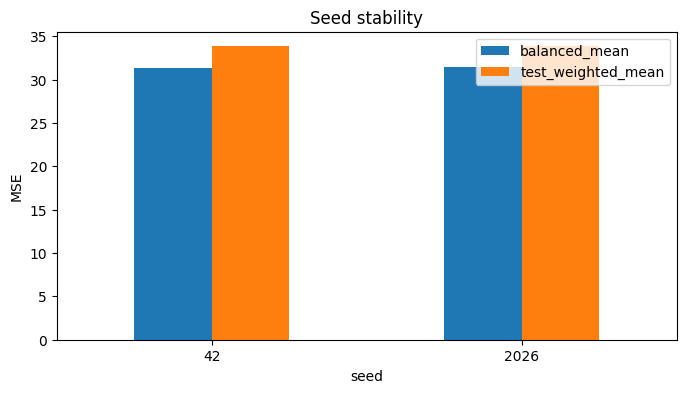

In [9]:
seed_predictions=[]; seed_rows=[]; seed_epochs=[]
for seed in tqdm(SEEDS,desc='Stride-1 seed confirmation'):
    model,log,best_epoch,best=train_neural(best_config,final_train_times,val_times,road_mean,road_std,global_scaler,regime_clf,seed,SEED_SEARCH_EPOCHS)
    _,pred=evaluate_neural(model,val_loader_fixed,True,desc=f'seed {seed} validation'); blocks,balanced,weighted=score_details(val_y,pred)
    seed_predictions.append(pred.astype(np.float32)); seed_epochs.append(best_epoch)
    seed_rows.append({'seed':seed,'h5':balanced[0],'h10':balanced[1],'h15':balanced[2],'balanced_mean':balanced.mean(),'test_weighted_mean':weighted.mean(),'best_epoch':best_epoch})
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
seed_report=pd.DataFrame(seed_rows); display(seed_report.round(5))
val_pred_gnn=np.mean(seed_predictions,axis=0).astype(np.float32); gnn_blocks,gnn_balanced,gnn_weighted=score_details(val_y,val_pred_gnn)
refit_epochs=max(1,int(np.median(seed_epochs)))
print('Seed-average balanced:',gnn_balanced.round(5),'mean',gnn_balanced.mean())
print('Seed-average test-weighted:',gnn_weighted.round(5),'mean',gnn_weighted.mean(),'| refit epochs:',refit_epochs)
seed_report.set_index('seed')[['balanced_mean','test_weighted_mean']].plot(kind='bar',figsize=(8,4),title='Seed stability'); plt.ylabel('MSE'); plt.xticks(rotation=0); plt.show()


## 10. Cross-fitted ensemble-weight stability

Same-fold simplex weights made V5's 31.03 diagnostic optimistic. Here the held-out days are split into two disjoint calibration halves. We fit weights on A and score B, then fit on B and score A. The primary score is this cross-fitted prediction; final test weights are the average of both fits. A full-validation fit is printed only as an optimistic diagnostic.


Weight calibration/evaluation origins: 2001 1338 | block counts A: [1339  662] B: [1007  331]


,horizon,weight_L1_A_vs_B,w_AR,w_PCA,w_DLR_r48_a30_resid_soft,w_DLR_r64_a30_resid_soft,w_GNN
0,h5,0.106525,0.000000,0.020388,0.081696,0.364635,0.533280
1,h10,0.124770,0.022943,0.020198,0.242629,0.379429,0.334802
2,h15,0.204198,0.051050,0.031731,0.284833,0.377293,0.255093


V6 PRIMARY cross-fitted balanced / inferred-test-weighted: 29.161325454711914 31.258721462613796
V6 robust averaged-weight diagnostic: 29.0872802734375 31.16884560983946
V5 same-fold weighted reference (not directly comparable): 31.030484


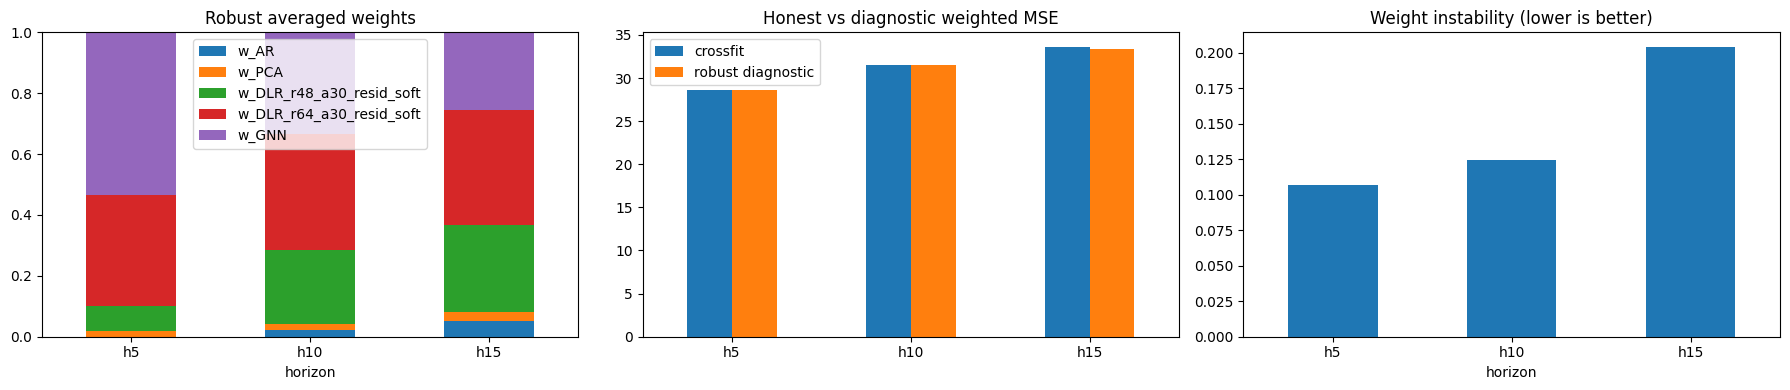

In [10]:
model_names=['AR','PCA']+direct_selected_names+['GNN']
val_candidates=[val_pred_ar,val_pred_pca]+direct_selected_predictions+[val_pred_gnn]
val_blocks=np.r_[np.zeros(VAL_LENGTHS[0],dtype=np.int8),np.ones(VAL_LENGTHS[1],dtype=np.int8)]
val_days=np.concatenate([t//DAY_LEN for t in val_times])
cal_mask=np.zeros(len(val_y),dtype=bool); offset=0
for b,times in enumerate(val_times):
    days=times//DAY_LEN; unique=np.unique(days)
    group_a=set(unique[::2].tolist())
    cal_mask[offset:offset+len(times)]=np.array([d in group_a for d in days]); offset+=len(times)
if cal_mask.all() or (~cal_mask).all():
    # FAST_MODE may retain only one held-out day. Alternate origins so the smoke
    # test still exercises both weight-fitting directions.
    cal_mask=np.arange(len(val_y))%2==0
print('Weight calibration/evaluation origins:',int(cal_mask.sum()),int((~cal_mask).sum()),
      '| block counts A:',np.bincount(val_blocks[cal_mask],minlength=2),
      'B:',np.bincount(val_blocks[~cal_mask],minlength=2))

def simplex_weights_subset(y,preds,mask):
    X=np.stack([p[mask].reshape(-1).astype(np.float64) for p in preds],1)
    yy=y[mask].reshape(-1).astype(np.float64); blocks=val_blocks[mask]
    counts=np.bincount(blocks,minlength=2)
    sample_w=np.array([TEST_BLOCK_WEIGHTS[b]/max(1,counts[b]) for b in blocks])
    w=np.repeat(sample_w,N_ROADS); w=w/w.sum(); G=X.T@(X*w[:,None]); c=X.T@(yy*w)
    fun=lambda a:float(a@G@a-2*c@a); jac=lambda a:2*G@a-2*c
    result=minimize(fun,np.full(len(preds),1/len(preds)),jac=jac,bounds=[(0,1)]*len(preds),
                    constraints={'type':'eq','fun':lambda a:a.sum()-1},method='SLSQP',
                    options={'ftol':1e-12,'maxiter':300})
    assert result.success,result.message; return result.x

blend_weights=[]; fullfit_weights=[]; robust_parts=[]; crossfit_parts=[]; blend_rows=[]
for i,h in enumerate(HORIZONS):
    horizon_preds=[p[...,i] for p in val_candidates]
    w_a=simplex_weights_subset(val_y[...,i],horizon_preds,cal_mask)
    w_b=simplex_weights_subset(val_y[...,i],horizon_preds,~cal_mask)
    w_full=simplex_weights_subset(val_y[...,i],horizon_preds,np.ones(len(val_y),dtype=bool))
    w_robust=(w_a+w_b)/2; w_robust=w_robust/w_robust.sum()
    robust=sum(w_robust[j]*horizon_preds[j] for j in range(len(model_names)))
    cross=np.empty_like(robust)
    cross[cal_mask]=sum(w_b[j]*horizon_preds[j][cal_mask] for j in range(len(model_names)))
    cross[~cal_mask]=sum(w_a[j]*horizon_preds[j][~cal_mask] for j in range(len(model_names)))
    blend_weights.append(w_robust); fullfit_weights.append(w_full)
    robust_parts.append(robust.astype(np.float32)); crossfit_parts.append(cross.astype(np.float32))
    blend_rows.append({'horizon':f'h{h}','weight_L1_A_vs_B':np.abs(w_a-w_b).sum(),
                       **{f'w_{n}':w_robust[j] for j,n in enumerate(model_names)}})

W=np.asarray(blend_weights,dtype=np.float32)
val_pred_blend=np.stack(robust_parts,-1); val_pred_crossfit=np.stack(crossfit_parts,-1)
blend_blocks,blend_balanced,blend_weighted=score_details(val_y,val_pred_blend)
crossfit_blocks,crossfit_balanced,crossfit_weighted=score_details(val_y,val_pred_crossfit)
blend_report=pd.DataFrame(blend_rows)
display(blend_report.round(6))
print('V6 PRIMARY cross-fitted balanced / inferred-test-weighted:',float(crossfit_balanced.mean()),float(crossfit_weighted.mean()))
print('V6 robust averaged-weight diagnostic:',float(blend_balanced.mean()),float(blend_weighted.mean()))
print('V5 same-fold weighted reference (not directly comparable): 31.030484')

fig,ax=plt.subplots(1,3,figsize=(18,4))
blend_report.set_index('horizon')[[f'w_{n}' for n in model_names]].plot(kind='bar',stacked=True,ax=ax[0],ylim=(0,1),title='Robust averaged weights'); ax[0].tick_params(axis='x',rotation=0)
pd.DataFrame({'crossfit':crossfit_weighted,'robust diagnostic':blend_weighted},index=[f'h{h}' for h in HORIZONS]).plot(kind='bar',ax=ax[1],title='Honest vs diagnostic weighted MSE'); ax[1].tick_params(axis='x',rotation=0)
blend_report.plot(x='horizon',y='weight_L1_A_vs_B',kind='bar',ax=ax[2],legend=False,title='Weight instability (lower is better)'); ax[2].tick_params(axis='x',rotation=0)
plt.tight_layout(); plt.show()

selected_direct_rows=direct_report[direct_report.model.isin(direct_selected_names)].copy()
experiment_results=pd.concat([
    baseline.rename(columns={'mean':'balanced_mean'}),ablation_report.drop(columns=['best_epoch']),selected_direct_rows,
    pd.DataFrame([{'model':'GNN_2seed_average','h5':gnn_balanced[0],'h10':gnn_balanced[1],'h15':gnn_balanced[2],'balanced_mean':gnn_balanced.mean(),'test_weighted_mean':gnn_weighted.mean()}]),
    pd.DataFrame([{'model':'V6_crossfit_blend','h5':crossfit_balanced[0],'h10':crossfit_balanced[1],'h15':crossfit_balanced[2],'balanced_mean':crossfit_balanced.mean(),'test_weighted_mean':crossfit_weighted.mean()}]),
    pd.DataFrame([{'model':'V6_robust_weight_diagnostic','h5':blend_balanced[0],'h10':blend_balanced[1],'h15':blend_balanced[2],'balanced_mean':blend_balanced.mean(),'test_weighted_mean':blend_weighted.mean()}])
],ignore_index=True,sort=False)
experiment_results.to_csv(OUTPUT_DIR/'v6_experiment_results.csv',index=False)


## 11. Full-data refit and test inference

Only the DirectLR base specifications that won at least one horizon/mean criterion are refit. This keeps runtime and memory bounded. The test blend uses the averaged A/B weights—not the optimistic full-validation weights.


In [11]:
full_times=[valid_times(len(z),HISTORY-1,len(z),FINAL_STRIDE) for z in train_speeds]
if FAST_MODE: full_times=[t[-min(110,len(t)):] for t in full_times]
ar_full=fit_shared_ar(full_times,max_timestamps_per_block=1800); test_pred_ar=predict_ar_histories(ar_full,test_hist,desc='Full AR test')
pca_full=fit_road_pca([np.ones(len(z),dtype=bool) for z in train_speeds]); F_full=pca_features_times(pca_full,full_times); F_test=pca_features_hist(pca_full,test_hist,desc='PCA test')
Y_full,B_full=targets_bases(full_times,ar_full); test_pca_parts=[]
for i,h in enumerate(tqdm(HORIZONS,desc='Full PCA ridge')):
    m=Ridge(alpha=pca_best_alpha[h]).fit(F_full,Y_full[...,i]-B_full[...,i]); test_pca_parts.append(test_pred_ar[...,i]+m.predict(F_test))
test_pred_pca=np.stack(test_pca_parts,-1).astype(np.float32); del F_full,Y_full,B_full; gc.collect()

selected_base_specs=sorted(set(tuple(info['spec']) for info in direct_selected.values()))
direct_lr_full=DirectLowRankFamily(max(DIRECT_RANKS),selected_base_specs).fit(full_times,[np.ones(len(z),dtype=bool) for z in train_speeds])
test_direct_map={}; base_cache={}
for name,info in tqdm(direct_selected.items(),desc='Selected DirectLR test variants'):
    spec=tuple(info['spec'])
    if spec not in base_cache: base_cache[spec]=direct_lr_full.predict_base(test_hist,spec,desc=f'full {name}')
    test_direct_map[name]=direct_lr_full.add_local_residual(base_cache[spec],test_hist,info['scales'])

full_global,full_regime_y=global_features_for_times(full_times,desc='Full global context')
full_scaler=StandardScaler().fit(full_global); full_regime_clf=LogisticRegression(C=.1,max_iter=1000,random_state=BASE_SEED).fit(full_scaler.transform(full_global),full_regime_y)
all_rows=np.concatenate([np.asarray(z,dtype=np.float32) for z in train_speeds]); full_mean=all_rows.mean(0).astype(np.float32); full_std=(all_rows.std(0)+3.).astype(np.float32); del all_rows,full_global; gc.collect()

class TestDataset(Dataset):
    def __len__(self): return len(test_hist)
    def __getitem__(self,i): return torch.from_numpy(np.asarray(test_hist[i],dtype=np.float32).T.copy()),torch.from_numpy(test_text_z[i])
test_loader=DataLoader(TestDataset(),batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=torch.cuda.is_available())
test_seed_predictions=[]
for seed in tqdm(SEEDS,desc='Full neural refits'):
    model,log,_,_=train_neural(best_config,full_times,None,full_mean,full_std,full_scaler,full_regime_clf,seed,refit_epochs)
    model.eval(); parts=[]
    with torch.no_grad():
        for hist,text in tqdm(test_loader,desc=f'test inference seed {seed}',leave=False):
            pred,_,_=model(hist.to(DEVICE),text.to(DEVICE)); parts.append(pred.cpu().numpy())
    test_seed_predictions.append(np.concatenate(parts).astype(np.float32))
    torch.save({'config':asdict(best_config),'seed':seed,'epochs':refit_epochs,'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()}},OUTPUT_DIR/f'v6_{best_config.name}_seed{seed}.pt')
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
test_pred_gnn=np.mean(test_seed_predictions,0).astype(np.float32)
test_candidates=[test_pred_ar,test_pred_pca]+[test_direct_map[n] for n in direct_selected_names]+[test_pred_gnn]
assert len(test_candidates)==len(model_names)==W.shape[1]
test_pred=np.empty_like(test_pred_ar)
for i in range(3): test_pred[...,i]=sum(W[i,j]*test_candidates[j][...,i] for j in range(len(model_names)))
test_pred=np.clip(test_pred,0,160).astype(np.float32)
print('Test prediction:',test_pred.shape,'range',float(test_pred.min()),float(test_pred.max()),'mean',float(test_pred.mean()))


full DLR_r48_a30_resid_soft:   0%|          | 0/9 [00:00<?, ?it/s]
                                                                  
global_film_ema_soft_moe seed=42: 100%|██████████| 7/7 [01:42<00:00, 15.20s/it, balanced=32.671, train=32.671, weighted=32.671]
                                                                                                                               
global_film_ema_soft_moe seed=2026: 100%|██████████| 7/7 [01:42<00:00, 14.45s/it, balanced=32.446, train=32.446, weighted=32.446]
                                                                                                                                 
Full neural refits: 100%|██████████| 2/2 [03:25<00:00, 102.87s/it]


Test prediction: (540, 1260, 3) range 0.0 99.1477279663086 mean 52.838809967041016


## 12. Submission audit dan visualisasi hasil

Urutan reshape mengikuti sample → horizon → road persis seperti sample submission. Audit memeriksa ID boundary, NaN, range, distribusi horizon, besar koreksi dari mean-last-3, dan horizon separation.


,horizon,mean,std,min,max,zeros,mean_abs_vs_mean3
0,h5,52.836281,19.499399,0.0,97.964432,15585,2.07360
1,h10,52.834610,19.397810,0.0,98.717171,14862,2.63486
2,h15,52.845539,19.361530,0.0,99.147728,15040,3.00545


Mean absolute h5-h10 / h10-h15: 0.7824326753616333 0.6028615832328796


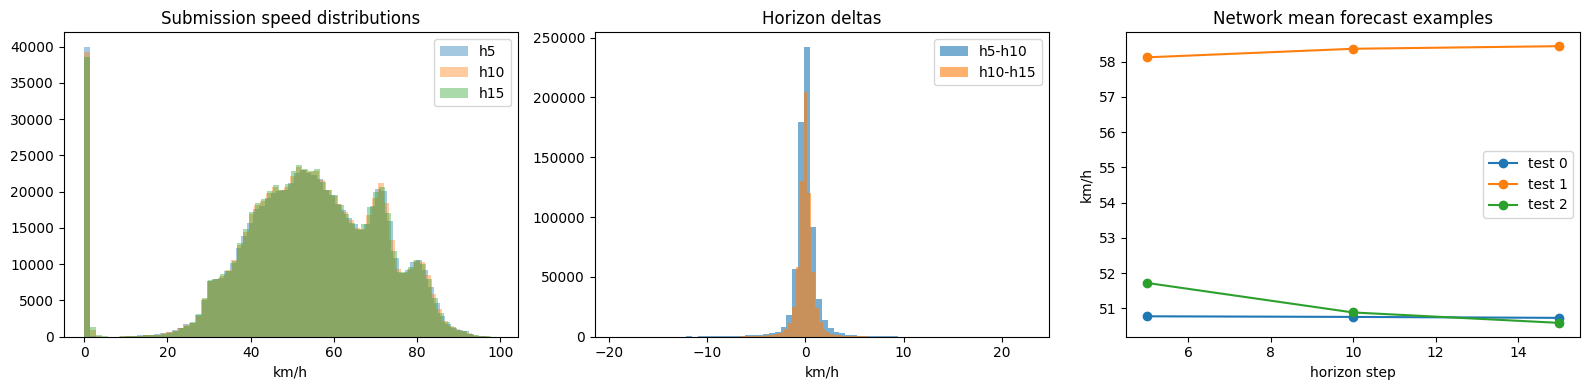

Saved: /kaggle/working/submission_v6.csv
Also saved: v6_experiment_results.csv, v6_diagnostics.json, and V6 seed checkpoints


,id,speed
0,test_00000_h5_r0,47.866920
1,test_00000_h5_r1,68.438995
2,test_00000_h5_r2,70.348976
2041197,test_00539_h15_r1257,63.184975
2041198,test_00539_h15_r1258,69.012962
2041199,test_00539_h15_r1259,0.003303


In [12]:
submission=sample_submission.copy(); flat=test_pred.transpose(0,2,1).reshape(-1)
assert len(flat)==len(submission); assert submission.id.iloc[0]=='test_00000_h5_r0'; assert submission.id.iloc[N_ROADS]=='test_00000_h10_r0'; assert submission.id.iloc[3*N_ROADS]=='test_00001_h5_r0'; assert submission.id.iloc[-1]=='test_00539_h15_r1259'
submission['speed']=flat; assert submission.speed.notna().all() and submission.speed.between(0,160).all()
submission_path=OUTPUT_DIR/'submission_v6.csv'; submission.to_csv(submission_path,index=False)

mean3=test_hist[:,-3:].mean(1); audit=[]
for i,h in enumerate(HORIZONS):
    x=test_pred[...,i]; audit.append({'horizon':f'h{h}','mean':x.mean(),'std':x.std(),'min':x.min(),'max':x.max(),'zeros':int(np.sum(x==0)),'mean_abs_vs_mean3':np.mean(np.abs(x-mean3))})
audit_df=pd.DataFrame(audit); display(audit_df.round(5)); print('Mean absolute h5-h10 / h10-h15:',float(np.mean(np.abs(test_pred[...,0]-test_pred[...,1]))),float(np.mean(np.abs(test_pred[...,1]-test_pred[...,2]))))

fig,ax=plt.subplots(1,3,figsize=(16,4))
for i,h in enumerate(HORIZONS): ax[0].hist(test_pred[...,i].ravel(),bins=70,alpha=.4,label=f'h{h}')
ax[0].set(title='Submission speed distributions',xlabel='km/h'); ax[0].legend()
ax[1].hist((test_pred[...,0]-test_pred[...,1]).ravel(),bins=70,alpha=.6,label='h5-h10'); ax[1].hist((test_pred[...,1]-test_pred[...,2]).ravel(),bins=70,alpha=.6,label='h10-h15'); ax[1].set(title='Horizon deltas',xlabel='km/h'); ax[1].legend()
sample_ids=[0,min(1,len(test_pred)-1),min(2,len(test_pred)-1)]
for s in sample_ids: ax[2].plot(HORIZONS,test_pred[s].mean(0),marker='o',label=f'test {s}')
ax[2].set(title='Network mean forecast examples',xlabel='horizon step',ylabel='km/h'); ax[2].legend(); plt.tight_layout(); plt.show()

diagnostics={'selected_config':asdict(best_config),'refit_epochs':refit_epochs,'test_block_weights':TEST_BLOCK_WEIGHTS.tolist(),'crossfit_balanced_validation_mse':float(crossfit_balanced.mean()),'crossfit_test_weighted_validation_mse':float(crossfit_weighted.mean()),'robust_weight_diagnostic_mse':float(blend_weighted.mean()),'ensemble_weights':W.tolist(),'model_names':model_names,'weight_stability_L1':blend_report.weight_L1_A_vs_B.tolist(),'selected_direct_variants':{n:{'spec':list(direct_selected[n]['spec']),'scales':list(direct_selected[n]['scales'])} for n in direct_selected_names},'submission_rows':len(submission)}
(OUTPUT_DIR/'v6_diagnostics.json').write_text(json.dumps(diagnostics,indent=2))
print('Saved:',submission_path); print('Also saved: v6_experiment_results.csv, v6_diagnostics.json, and V6 seed checkpoints')
display(pd.concat([submission.head(3),submission.tail(3)]))


## 13. How to decide after the run

1. **Submit V5 first** because it is already audited and provides a safe checkpoint.
2. Read `V6 PRIMARY cross-fitted ...`; this is the fairest ensemble-weight diagnostic in this notebook.
3. Check `weight_L1_A_vs_B`. Small values and similar DirectLR choices across horizons are stronger evidence than a tiny same-fold gain.
4. Submit V6 separately if the primary cross-fit metric is competitive and no component receives wildly unstable weights.
5. A leaderboard score remains the final test because train/test distribution shift is material. Do not interpret any one local number as guaranteed public MSE.

The notebook intentionally retains EDA tables, plots, text summaries, `tqdm`, experiment CSV, diagnostics JSON, checkpoints, and strict submission assertions.
